In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

============================================================
1. LOAD DATASET
============================================================

In [5]:
print("=" * 60)
print("CUSTOMER CHURN CLASSIFICATION")
print("=" * 60)

CUSTOMER CHURN CLASSIFICATION


In [6]:
file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

In [7]:
df = pd.read_csv(file_path)

In [8]:
print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (7043, 21)


============================================================
2. UNDERSTAND THE DATA
============================================================

In [9]:
print("\nFirst 5 rows:")
print(df.head())


First 5 rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies      

In [10]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [11]:
print("\nDataset information:")
print(df.info())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [12]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


============================================================
3. DATA CLEANING
============================================================

TotalCharges contains some blank values.
Convert it to numeric. Invalid values become NaN.

In [13]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

Remove rows where TotalCharges is missing

In [14]:
df = df.dropna(subset=["TotalCharges"])

In [15]:
print("\nShape after cleaning:", df.shape)


Shape after cleaning: (7032, 21)


============================================================
4. REMOVE UNNECESSARY COLUMN
============================================================

customerID is only an identifier and is not useful
for predicting churn.

In [16]:
df = df.drop("customerID", axis=1)

============================================================
5. CONVERT TARGET VARIABLE
============================================================

Churn:
Yes = 1
No  = 0

In [17]:
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

============================================================
6. EXPLORATORY DATA ANALYSIS
============================================================

In [18]:
plt.figure(figsize=(6, 4))

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Axes: xlabel='Churn', ylabel='count'>

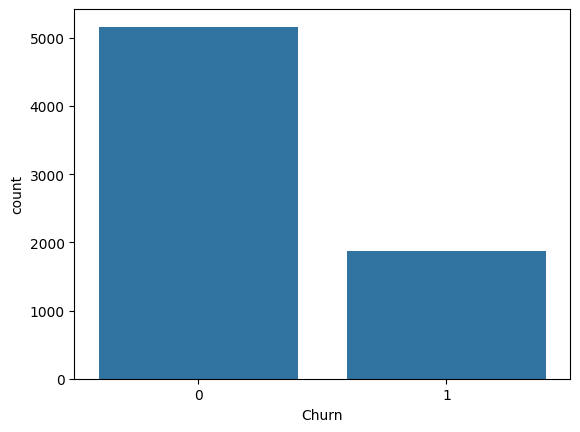

In [19]:
sns.countplot(
    x="Churn",
    data=df
)

Text(0, 0.5, 'Number of Customers')

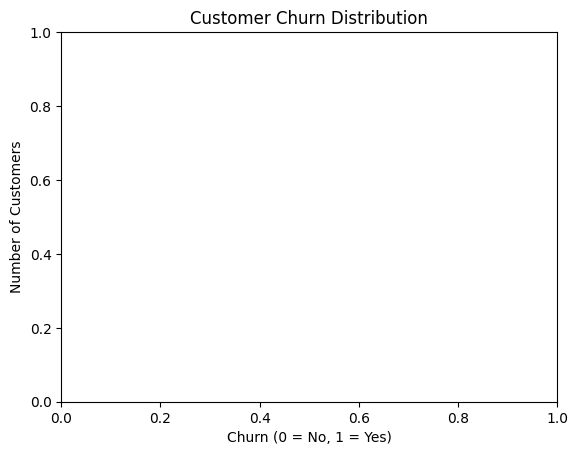

In [20]:
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

In [21]:
plt.tight_layout()
plt.savefig("churn_distribution.png")
plt.show()

<Figure size 640x480 with 0 Axes>

============================================================
7. SEPARATE FEATURES AND TARGET
============================================================

In [22]:
X = df.drop("Churn", axis=1)

In [23]:
y = df["Churn"]

============================================================
8. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
============================================================

In [24]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

In [25]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

In [26]:
print("\nNumerical features:")
print(numerical_features)


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [27]:
print("\nCategorical features:")
print(categorical_features)


Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


============================================================
9. DATA PREPROCESSING
============================================================

Numerical features:
StandardScaler standardizes numerical values.

Categorical features:
OneHotEncoder converts categories into numerical values.

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

============================================================
10. TRAIN / TEST SPLIT
============================================================

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [30]:
print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (5625, 19)
Testing data: (1407, 19)


============================================================
11. LOGISTIC REGRESSION MODEL
============================================================

In [31]:
logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

============================================================
12. RANDOM FOREST MODEL
============================================================

In [32]:
random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

============================================================
13. TRAIN LOGISTIC REGRESSION
============================================================

In [33]:
print("\n" + "=" * 60)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 60)


TRAINING LOGISTIC REGRESSION


In [34]:
logistic_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
logistic_predictions = logistic_model.predict(
    X_test
)

In [36]:
logistic_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

============================================================
14. TRAIN RANDOM FOREST
============================================================

In [37]:
print("\n" + "=" * 60)
print("TRAINING RANDOM FOREST")
print("=" * 60)


TRAINING RANDOM FOREST


In [38]:
random_forest_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [39]:
rf_predictions = random_forest_model.predict(
    X_test
)

In [40]:
rf_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

============================================================
15. EVALUATION FUNCTION
============================================================

In [41]:
def evaluate_model(
    model_name,
    y_true,
    predictions,
    probabilities
):

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    precision = precision_score(
        y_true,
        predictions
    )

    recall = recall_score(
        y_true,
        predictions
    )

    f1 = f1_score(
        y_true,
        predictions
    )

    roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            predictions
        )
    )

    return [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]

============================================================
16. EVALUATE BOTH MODELS
============================================================

In [42]:
logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions,
    logistic_probabilities
)


Logistic Regression
Accuracy  : 0.8038
Precision : 0.6485
Recall    : 0.5722
F1-Score  : 0.6080
ROC-AUC   : 0.8359

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [43]:
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)


Random Forest
Accuracy  : 0.7896
Precision : 0.6345
Recall    : 0.4920
F1-Score  : 0.5542
ROC-AUC   : 0.8140

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.63      0.49      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.71      1407
weighted avg       0.78      0.79      0.78      1407



============================================================
17. MODEL COMPARISON
============================================================

In [44]:
results = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC"
        ],
        "Logistic Regression": logistic_results,
        "Random Forest": rf_results
    }
)

In [45]:
print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)


MODEL COMPARISON


In [46]:
print(results)

      Metric  Logistic Regression  Random Forest
0   Accuracy             0.803838       0.789623
1  Precision             0.648485       0.634483
2     Recall             0.572193       0.491979
3   F1-Score             0.607955       0.554217
4    ROC-AUC             0.835929       0.813999


============================================================
18. SAVE MODEL COMPARISON
============================================================

In [47]:
results.to_csv(
    "model_comparison.csv",
    index=False
)

============================================================
19. MODEL COMPARISON PLOT
============================================================

In [48]:
results_plot = results.set_index("Metric")

<Axes: xlabel='Metric'>

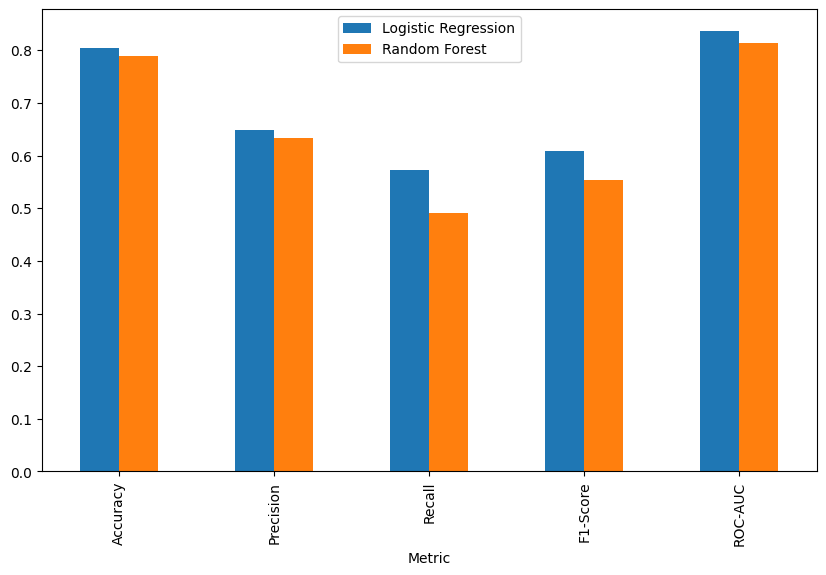

In [49]:
results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

(0.0, 1.0)

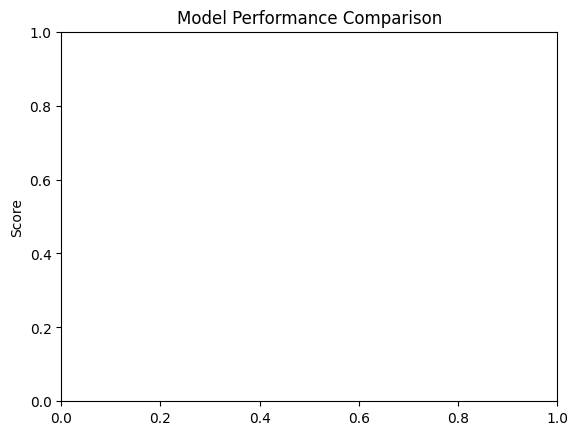

In [50]:
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

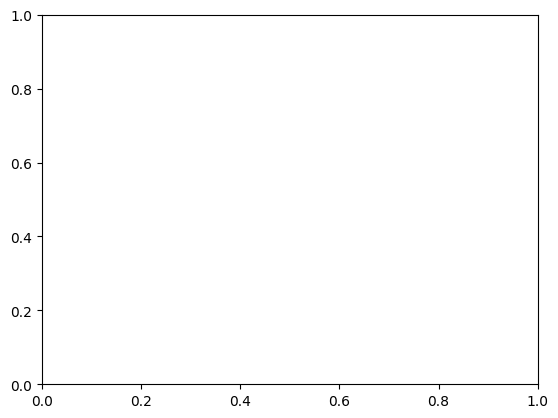

In [51]:
plt.xticks(
    rotation=0
)

C:\Users\admin\AppData\Local\Temp\ipykernel_4528\1653824425.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(


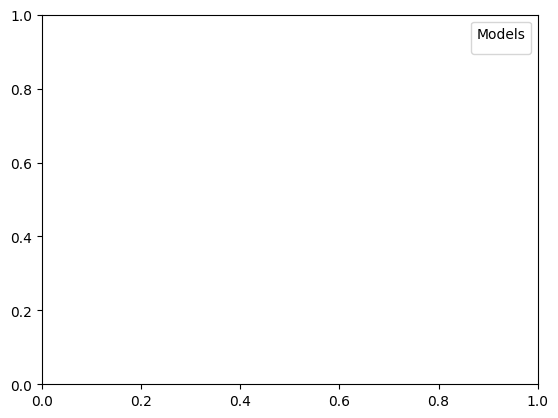

In [52]:
plt.legend(
    title="Models"
)

In [53]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [54]:
plt.savefig(
    "model_comparison.png"
)

<Figure size 640x480 with 0 Axes>

In [55]:
plt.show()

============================================================
20. CONFUSION MATRIX - LOGISTIC REGRESSION
============================================================

In [56]:
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions
)

In [57]:
plt.figure(figsize=(6, 5))

<Figure size 600x500 with 0 Axes>

<Figure size 600x500 with 0 Axes>

<Axes: >

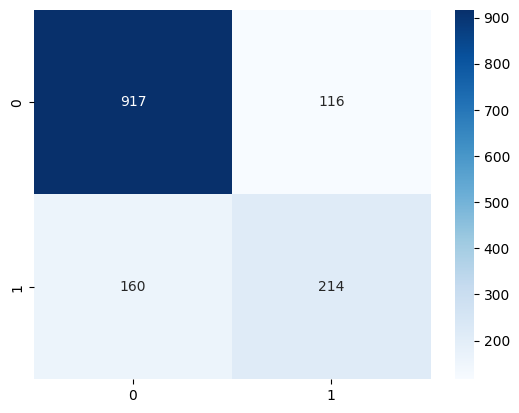

In [58]:
sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

Text(0.5, 1.0, 'Confusion Matrix - Logistic Regression')

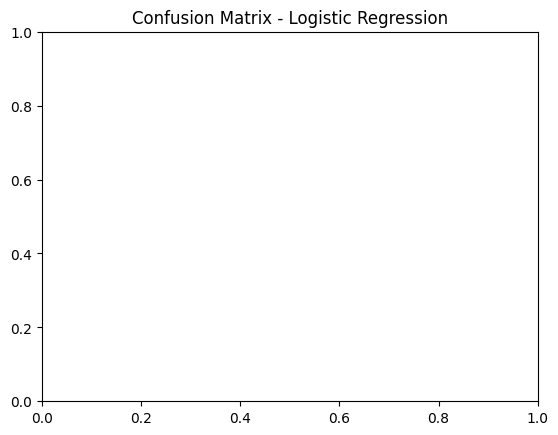

In [59]:
plt.title(
    "Confusion Matrix - Logistic Regression"
)

Text(0, 0.5, 'Actual')

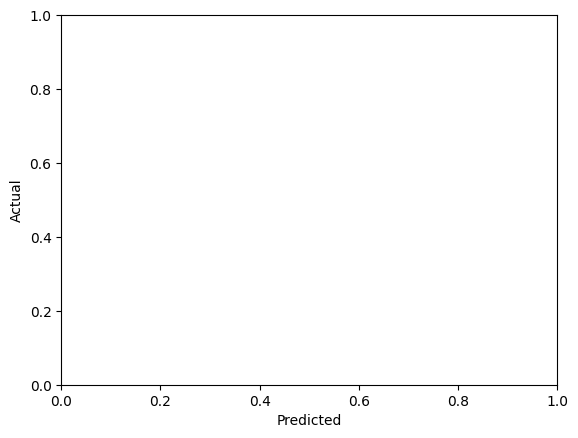

In [60]:
plt.xlabel("Predicted")
plt.ylabel("Actual")

In [61]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [62]:
plt.savefig(
    "logistic_confusion_matrix.png"
)

<Figure size 640x480 with 0 Axes>

In [63]:
plt.show()

============================================================
21. CONFUSION MATRIX - RANDOM FOREST
============================================================

In [64]:
rf_cm = confusion_matrix(
    y_test,
    rf_predictions
)

In [65]:
plt.figure(figsize=(6, 5))

<Figure size 600x500 with 0 Axes>

<Figure size 600x500 with 0 Axes>

<Axes: >

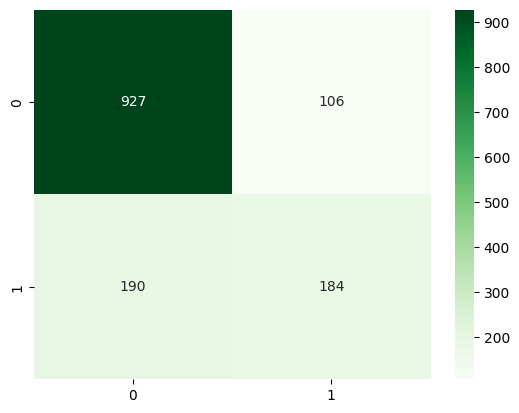

In [66]:
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

Text(0.5, 1.0, 'Confusion Matrix - Random Forest')

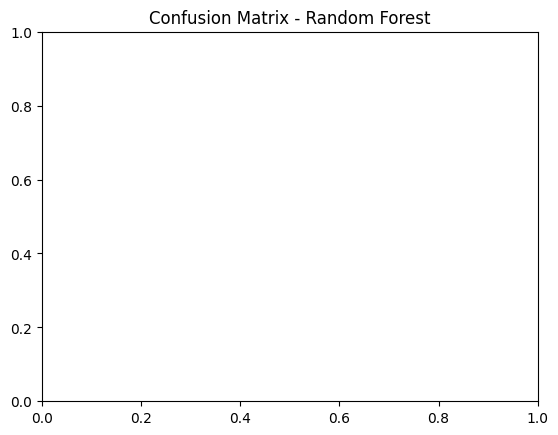

In [67]:
plt.title(
    "Confusion Matrix - Random Forest"
)

Text(0, 0.5, 'Actual')

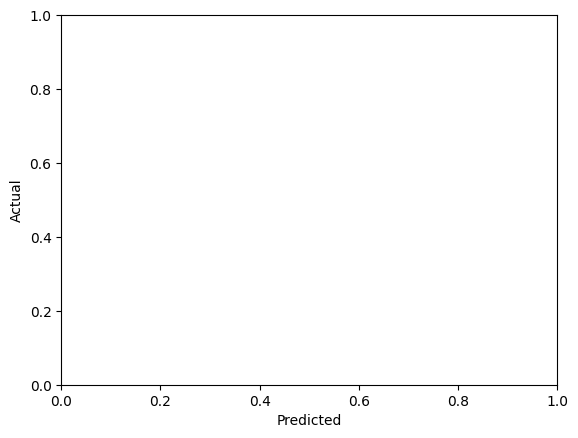

In [68]:
plt.xlabel("Predicted")
plt.ylabel("Actual")

In [69]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [70]:
plt.savefig(
    "random_forest_confusion_matrix.png"
)

<Figure size 640x480 with 0 Axes>

In [71]:
plt.show()

============================================================
22. ROC CURVE
============================================================

In [72]:
logistic_fpr, logistic_tpr, _ = roc_curve(
    y_test,
    logistic_probabilities
)

In [73]:
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

In [74]:
plt.figure(figsize=(8, 6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

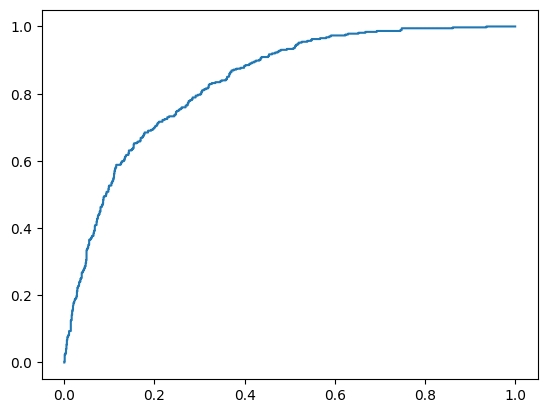

In [75]:
plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, logistic_probabilities):.3f})"
)

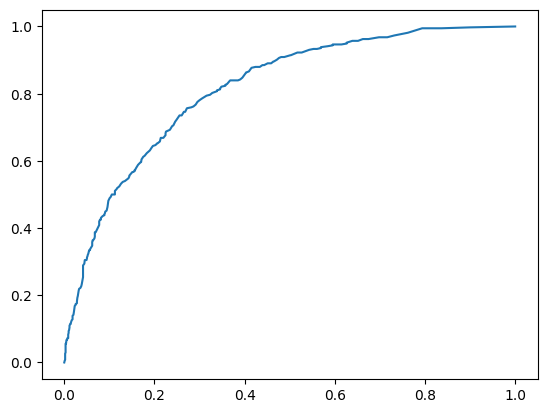

In [76]:
plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_probabilities):.3f})"
)

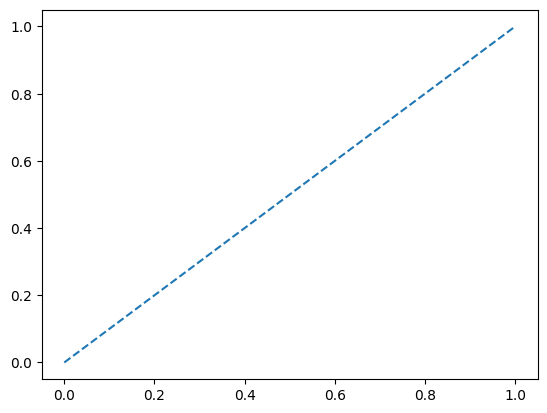

In [77]:
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

Text(0, 0.5, 'True Positive Rate')

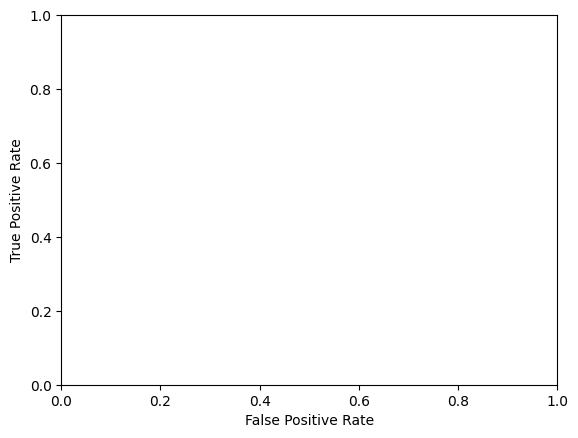

In [78]:
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

Text(0.5, 1.0, 'ROC Curve Comparison')

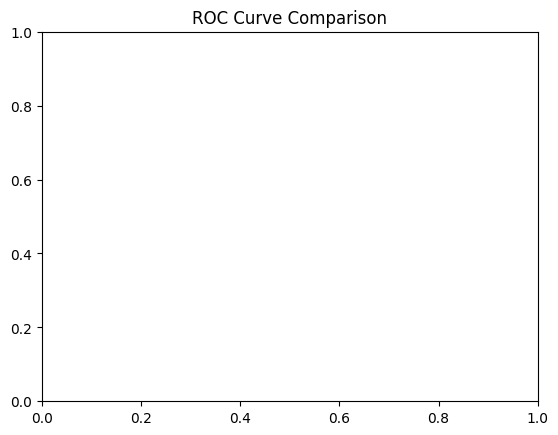

In [79]:
plt.title("ROC Curve Comparison")

C:\Users\admin\AppData\Local\Temp\ipykernel_4528\4061938096.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


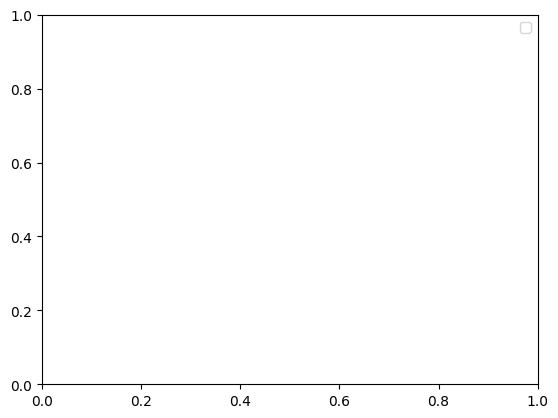

In [80]:
plt.legend()

In [81]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [82]:
plt.savefig(
    "roc_curve.png"
)

<Figure size 640x480 with 0 Axes>

In [83]:
plt.show()

============================================================
23. RANDOM FOREST FEATURE IMPORTANCE
============================================================

Get the trained preprocessing step

In [84]:
rf_preprocessor = random_forest_model.named_steps[
    "preprocessor"
]

In [85]:
rf_classifier = random_forest_model.named_steps[
    "classifier"
]

Get transformed feature names

In [86]:
feature_names = rf_preprocessor.get_feature_names_out()

In [87]:
feature_importance = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": rf_classifier.feature_importances_
    }
)

In [88]:
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

In [89]:
print("\n" + "=" * 60)
print("TOP 15 IMPORTANT FEATURES")
print("=" * 60)


TOP 15 IMPORTANT FEATURES


In [90]:
print(
    feature_importance.head(15)
)

                                Feature  Importance
3                     num__TotalCharges    0.158200
1                           num__tenure    0.142352
2                   num__MonthlyCharges    0.136054
36         cat__Contract_Month-to-month    0.053717
18               cat__OnlineSecurity_No    0.031239
43  cat__PaymentMethod_Electronic check    0.029722
16     cat__InternetService_Fiber optic    0.026950
27                  cat__TechSupport_No    0.026900
0                    num__SeniorCitizen    0.020199
21                 cat__OnlineBackup_No    0.018778
5                      cat__gender_Male    0.018441
38               cat__Contract_Two year    0.018432
4                    cat__gender_Female    0.017810
24             cat__DeviceProtection_No    0.015518
39             cat__PaperlessBilling_No    0.015492


============================================================
24. FEATURE IMPORTANCE PLOT
============================================================

In [91]:
top_features = feature_importance.head(15)

In [92]:
plt.figure(figsize=(10, 7))

<Figure size 1000x700 with 0 Axes>

<Figure size 1000x700 with 0 Axes>

<Axes: xlabel='Importance', ylabel='Feature'>

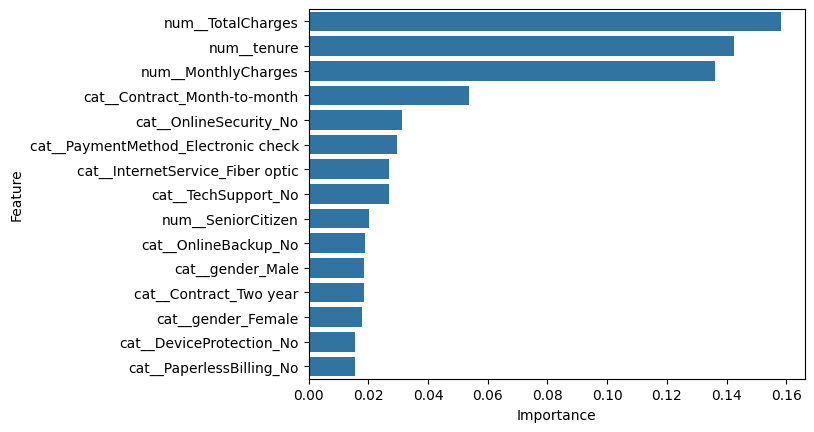

In [93]:
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

Text(0.5, 1.0, 'Top 15 Random Forest Feature Importances')

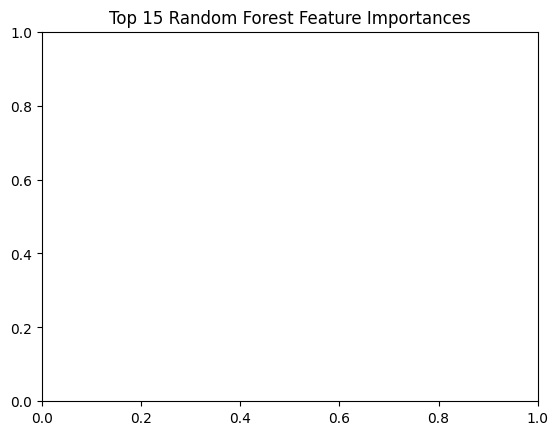

In [94]:
plt.title(
    "Top 15 Random Forest Feature Importances"
)

In [95]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [96]:
plt.savefig(
    "feature_importance.png"
)

<Figure size 640x480 with 0 Axes>

In [97]:
plt.show()

============================================================
25. CROSS-VALIDATION
============================================================

In [98]:
print("\n" + "=" * 60)
print("5-FOLD CROSS-VALIDATION")
print("=" * 60)


5-FOLD CROSS-VALIDATION


In [99]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [100]:
logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

In [101]:
rf_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

In [102]:
print("\nLogistic Regression CV Scores:")
print(logistic_cv_scores)


Logistic Regression CV Scores:
[0.81155556 0.79022222 0.78933333 0.80266667 0.81866667]


In [103]:
print(
    "Logistic Regression Mean CV Accuracy:",
    logistic_cv_scores.mean()
)

Logistic Regression Mean CV Accuracy: 0.8024888888888888


In [104]:
print("\nRandom Forest CV Scores:")
print(rf_cv_scores)


Random Forest CV Scores:
[0.79822222 0.78222222 0.78844444 0.78844444 0.79466667]


In [105]:
print(
    "Random Forest Mean CV Accuracy:",
    rf_cv_scores.mean()
)

Random Forest Mean CV Accuracy: 0.7904


============================================================
26. FINAL SUMMARY
============================================================

In [106]:
print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)


FINAL SUMMARY


In [107]:
print(
    f"Logistic Regression Test Accuracy: "
    f"{logistic_results[0]:.4f}"
)

Logistic Regression Test Accuracy: 0.8038


In [108]:
print(
    f"Random Forest Test Accuracy: "
    f"{rf_results[0]:.4f}"
)

Random Forest Test Accuracy: 0.7896


In [109]:
print(
    f"Logistic Regression Mean CV Accuracy: "
    f"{logistic_cv_scores.mean():.4f}"
)

Logistic Regression Mean CV Accuracy: 0.8025


In [110]:
print(
    f"Random Forest Mean CV Accuracy: "
    f"{rf_cv_scores.mean():.4f}"
)

Random Forest Mean CV Accuracy: 0.7904


In [111]:
print("\nAll Task 1 requirements completed!")


All Task 1 requirements completed!


In [112]:
print("\nGenerated files:")
print("1. churn_distribution.png")
print("2. model_comparison.png")
print("3. model_comparison.csv")
print("4. logistic_confusion_matrix.png")
print("5. random_forest_confusion_matrix.png")
print("6. roc_curve.png")
print("7. feature_importance.png")


Generated files:
1. churn_distribution.png
2. model_comparison.png
3. model_comparison.csv
4. logistic_confusion_matrix.png
5. random_forest_confusion_matrix.png
6. roc_curve.png
7. feature_importance.png
